# Cosine Similarity: Aligned Pairs and Pairwise Matrices

Cosine similarity compares the **direction** of two vectors, ignoring their length:

$$\cos(a, b) = \frac{a \cdot b}{\lVert a\rVert\,\lVert b\rVert} \in [-1, 1].$$

`braintools.metric` has two families:

| Function | Inputs | Output |
|---|---|---|
| `cosine_similarity(predictions, targets, epsilon=1e-8)` | two arrays `[..., d]` of matched pairs | `[...]`: one value per pair |
| `cosine_distance(predictions, targets, epsilon=1e-8)` | same | `1 - cosine_similarity` |
| `pairwise_cosine_similarity(X, Y=None)` | `X: (n, d)`, `Y: (m, d)` | `(n, m)` matrix of all pairs (`Y=None` means `X` against itself) |
| `pairwise_cosine_distance(X, Y=None)` | same | `1 - pairwise_cosine_similarity` |

Use the aligned version as a loss between predictions and targets, and the pairwise version for retrieval or for comparing population activity patterns.

## 1. Setup

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax

import braintools.metric as bm

## 2. Aligned Pairs

In [2]:
pred = jnp.array([[1.0, 0.0, 0.0],
                  [0.0, 1.0, 0.0],
                  [1.0, 1.0, 0.0],
                  [2.0, 2.0, 0.0]])
targ = jnp.array([[3.0, 0.0, 0.0],   # same direction, different length
                  [1.0, 0.0, 0.0],   # orthogonal
                  [0.0, 1.0, 0.0],   # 45 degrees
                  [-1.0, -1.0, 0.0]])  # opposite
print("similarity:", bm.cosine_similarity(pred, targ))
print("distance:  ", bm.cosine_distance(pred, targ))
print("optax:     ", optax.cosine_similarity(pred, targ))
print("zero vector with epsilon stays finite:", bm.cosine_similarity(jnp.zeros((1, 3)), targ[:1]))

similarity: [ 1.          0.          0.70710677 -0.99999994]
distance:   [0.         1.         0.29289323 2.        ]
optax:      [ 1.          0.          0.70710677 -0.99999994]


zero vector with epsilon stays finite: [0.]


As a loss, cosine distance only constrains direction. Fitting a linear map with it recovers the target directions, but the output length is arbitrary:

In [3]:
kx, kw = jax.random.split(jax.random.PRNGKey(0))
X = jax.random.normal(kx, (256, 8))
W_true = jax.random.normal(kw, (8, 4))
Y = X @ W_true

loss = lambda W: bm.cosine_distance(X @ W, Y).mean()
W = 0.01 * jax.random.normal(jax.random.PRNGKey(1), (8, 4))
step = jax.jit(jax.grad(loss))
for _ in range(500):
    W = W - 1.0 * step(W)
print(f"mean cosine distance {float(loss(W)):.4f}; output norm / target norm = "
      f"{float(jnp.linalg.norm(X @ W) / jnp.linalg.norm(Y)):.3f} (not constrained)")

mean cosine distance 0.0020; output norm / target norm = 2.571 (not constrained)


## 3. Pairwise Matrices

`pairwise_cosine_similarity(X, Y)` normalizes every row and takes all dot products. Below it is checked against that definition, then used for nearest-neighbour retrieval.

In [4]:
rng = np.random.default_rng(0)
X = jnp.asarray(rng.normal(size=(5, 16)))
Y = jnp.asarray(rng.normal(size=(7, 16)))
S = bm.pairwise_cosine_similarity(X, Y)
ref = (X / jnp.linalg.norm(X, axis=1, keepdims=True)) @ (Y / jnp.linalg.norm(Y, axis=1, keepdims=True)).T
print("shape", S.shape, "max |difference| from definition:", float(jnp.max(jnp.abs(S - ref))))
print("pairwise_cosine_distance == 1 - similarity:", bool(jnp.allclose(bm.pairwise_cosine_distance(X, Y), 1 - S)))
print("X against itself: diagonal", jnp.diag(bm.pairwise_cosine_similarity(X)))

shape (5, 7) max |difference| from definition: 5.960464477539063e-08
pairwise_cosine_distance == 1 - similarity: True
X against itself: diagonal [0.99999994 0.99999994 0.9999999  1.0000002  1.        ]


In [5]:
# Retrieval: noisy queries should find the item they were made from
items = jnp.asarray(rng.normal(size=(100, 32)))
truth = rng.choice(100, 20, replace=False)
queries = items[truth] + 2.5 * jnp.asarray(rng.normal(size=(20, 32)))
S = bm.pairwise_cosine_similarity(queries, items)
top3 = jnp.argsort(-S, axis=1)[:, :3]
print(f"top-1 accuracy {float(jnp.mean(top3[:, 0] == truth)):.2f}, "
      f"top-3 accuracy {float(jnp.mean(jnp.any(top3 == truth[:, None], axis=1))):.2f}")

top-1 accuracy 0.45, top-3 accuracy 0.75


## 4. Comparing Population Activity Patterns

In neuroscience, cosine similarity is a common way to compare population vectors (for example the firing-rate vector of a population at different times or for different stimuli). A representational similarity matrix is simply `pairwise_cosine_similarity` of the condition-by-neuron response matrix. Here two groups of stimuli evoke patterns around two prototypes:

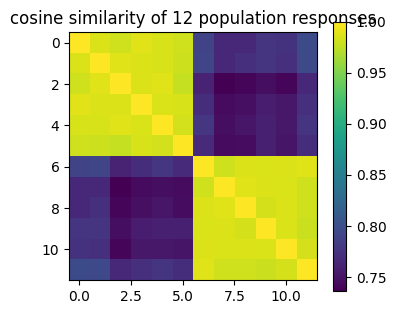

mean similarity within group 0.984, between groups 0.764


In [6]:
n_neurons = 60
proto = rng.random((2, n_neurons))  # non-negative "rate" prototypes
responses = np.concatenate([proto[0] + 0.3 * rng.random((6, n_neurons)),
                            proto[1] + 0.3 * rng.random((6, n_neurons))])
rsm = bm.pairwise_cosine_similarity(jnp.asarray(responses))

fig, ax = plt.subplots(figsize=(4, 3.5))
im = ax.imshow(rsm, cmap="viridis")
ax.set_title("cosine similarity of 12 population responses")
fig.colorbar(im, ax=ax)
plt.show()
within = float((rsm[:6, :6].sum() - 6) / 30)
between = float(rsm[:6, 6:].mean())
print(f"mean similarity within group {within:.3f}, between groups {between:.3f}")

Non-negative vectors such as firing rates always have cosine similarity $\ge 0$, so values are compressed toward 1; subtract the mean response across conditions first if you want to compare patterns of deviation.

## Summary

- `cosine_similarity` / `cosine_distance` work on matched pairs over the last axis; `epsilon` guards against zero vectors.
- `pairwise_cosine_similarity(X, Y)` returns the full `(n, m)` matrix; `Y=None` compares `X` with itself.
- Cosine measures direction only; use it when magnitude should not matter.